# Model predictions against the surveys the models never saw

The 2026-08 refresh added surveys the fitted panels do not contain. They are the only rows in this
project that test the models rather than describe their fit, so they get their own notebook.

**Two levels of "unseen", and they answer different questions.**

- **Held out** — the *country-year* is absent from the fitted panel. 17 surveys. The model may
  still have seen an earlier survey from the same country, so it knows roughly where that country
  sits; what it is being asked for is the movement since.
- **New country** — the *country* is absent from the panel entirely. 4 of the 17 (Mozambique,
  Nauru, Qatar, Vanuatu). This is the harder test, and with n = 4 it is an illustration, not a
  statistic — no correlation computed on four points means anything.

**One caveat applies to every number here and is not correctable:** the surveys measure ages
**15–49**; the models are fitted and predicted on **18+**. Part of every gap below is that
mismatch rather than model error.

Tables come from `src/14_coherent_ggi_comparison.py`. The GGI definitions are compared against
these same surveys in section G of `09_01_coherent_ggi_comparison.ipynb`; here the subject is the
**outcomes** — the predicted adoption levels and the ratio between them.

In [1]:
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import params

NOTEBOOK = '03_unseen_survey_validation'

warnings.filterwarnings('ignore')

STYLE = dict(params.STYLE); STYLE["save"]=True
PALETTE = STYLE['colors']
INK, MUTED, GRID = '#222222', '#666666', '#d9d9d9'
FIGDIR = params.fig_dir(NOTEBOOK)
FIGDIR.mkdir(parents=True, exist_ok=True)


def latest(stem):
    """most recent date-stamped build from src/14_coherent_ggi_comparison.py"""
    matches = sorted(f for f in params.table_dir('02_model_performance').glob(f'ggi_comparison_{stem}_*.csv')
                     if re.fullmatch(rf'ggi_comparison_{stem}_\d{{8}}\.csv', f.name))
    if not matches:
        raise FileNotFoundError(f'no ggi_comparison_{stem}_<date>.csv — '
                                'run src/14_coherent_ggi_comparison.py')
    return pd.read_csv(matches[-1])


def latest_gt(stem):
    """
    the survey-validation tables, which stage 03 (model performance) produces

    They score predicted against observed, so they belong to the model-performance step even
    though the GGI comparison also reads them — see doc/workflow.md.
    """
    matches = sorted(f for f in params.table_dir('02_model_performance').glob(
        f'model_performance_{stem}_*.csv')
        if re.fullmatch(rf'model_performance_{stem}_\d{{8}}\.csv', f.name))
    if not matches:
        raise FileNotFoundError(f'no model_performance_{stem}_<date>.csv — '
                                'run src/model_performance.py')
    return pd.read_csv(matches[-1])


unseen       = latest_gt('unseen_surveys')
levels       = latest_gt('groundtruth_levels')
level_stats  = latest_gt('groundtruth_level_stats')
gt           = latest_gt('groundtruth')
gt_stats     = latest_gt('groundtruth_stats')

INDICATORS = params.COHERENT_GGI['indicators']

# Observed and predicted are the two things being compared, so they take the first two hues of the
# project's categorical order (rebuilt for colour-vision accessibility in D23) and are backed by
# marker shape, so the pair survives a greyscale print.
OBS_COLOUR, PRED_COLOUR = PALETTE[0], PALETTE[1]
OBS_MARKER, PRED_MARKER = 'o', 'D'
NEW_COUNTRY_INK = PALETTE[2]

# Which predicted gender gap the level figure shows in its third column. The point of that column
# is to put the ratio beside the two levels it is built from, so it carries ONE definition — the
# comparison between definitions belongs in 09_01 section G, not here.
#   'direct'          the GGI the model predicts directly
#   'coherent_parity' the ratio of the (parity-capped) predicted levels — the project's primary
#   'coherent_raw'    the same, uncapped
GGI_DEFINITION = 'direct'

GGI_LABEL = {'direct': 'directly predicted',
             'coherent_parity': 'coherent, parity-capped',
             'coherent_raw': 'coherent, raw'}[GGI_DEFINITION]

# Which accuracy metric the bar chart shows. MAE and R2 disagree on purpose: MAE is the average
# miss in the units of the outcome, R2 is whether the model beats predicting the sample mean.
# R2 here is against the 1:1 line, so it charges for bias and scale error and can go negative —
# `pearson_r` in the tables is the association alone and stays high even when predictions are
# systematically off. A sample can look good on one and poor on the other; that is the point.
METRIC = 'mae'

METRIC_SPEC = {
    'mae':  dict(label='Mean absolute error against the survey', higher_is_better=False, fmt='{:.3f}'),
    'rmse': dict(label='RMSE against the survey',                higher_is_better=False, fmt='{:.3f}'),
    'r2':   dict(label='R² against the 1:1 line',                higher_is_better=True,  fmt='{:.2f}'),
}[METRIC]


def tidy(ax, title=None, xlabel=None, ylabel=None):
    """the project's axis treatment: recessive frame, muted labels"""
    if title:
        ax.set_title(title, fontsize=STYLE['label_fs'], color=INK, fontweight='bold', loc='left')
    for which, lab in (('x', xlabel), ('y', ylabel)):
        if lab:
            getattr(ax, f'set_{which}label')(lab, fontsize=STYLE['tick_fs'], color=MUTED)
    ax.tick_params(labelsize=STYLE['tick_fs'], colors=MUTED, length=3)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    return ax


n_surveys = unseen[unseen['indicator'] == 'internet'].shape[0]
n_new = unseen[(unseen['indicator'] == 'internet') & (~unseen['country_in_training'])].shape[0]
print(f'{n_surveys} unseen surveys | {n_new} of them from countries never in the fitted panel')
print(unseen[unseen['indicator'] == 'internet']
      .groupby('survey_type')['gid_0'].count().to_dict())

17 unseen surveys | 4 of them from countries never in the fitted panel
{'continuous dhs8': 1, 'dhs8': 11, 'mics6': 5}


## 1. Which surveys

Sorted by year. `country_in_training` is the second, harder sense of unseen: `False` means the
model had never seen that country at all.

In [2]:
(unseen[unseen['indicator'] == 'internet']
 [['gid_0', 'country', 'region', 'year', 'survey_type', 'country_in_training']]
 .rename(columns={'country_in_training': 'country_seen_in_panel'})
 .reset_index(drop=True))

,gid_0,country,region,year,survey_type,country_seen_in_panel
0,LSO,Lesotho,Sub-Saharan Africa,2022,dhs8,True
1,MOZ,Mozambique,Sub-Saharan Africa,2022,dhs8,False
2,AGO,Angola,Sub-Saharan Africa,2023,dhs8,True
3,COD,DR Congo,Sub-Saharan Africa,2023,dhs8,True
4,JOR,Jordan,Middle East & North Africa,2023,dhs8,True
5,LAO,Laos,East Asia & Pacific,2023,mics6,True
6,MLI,Mali,Sub-Saharan Africa,2023,dhs8,True
7,NRU,Nauru,East Asia & Pacific,2023,mics6,False
8,QAT,Qatar,Middle East & North Africa,2023,mics6,False
9,SEN,Senegal,Sub-Saharan Africa,2023,continuous dhs8,True


## 2. Predicted against observed

One point per survey, against the 1:1 line. Points **above** the line are countries the model reads
as more connected — or less unequal — than the survey found.

The first two columns are the outcomes the models actually fit; the third is the ratio built from
them, so an error in either level propagates into it. The third column carries **one** definition of
the gender gap, set by `GGI_DEFINITION` in the setup cell (`'direct'` by default,
`'coherent_parity'` or `'coherent_raw'` to swap). Comparing the three against each other is
section G of `09_01`, not this figure.

Only the **four largest misses in each panel** are named — labelling all 17 makes the plot
unreadable and the small errors are not the interesting ones. Countries the model had never seen at
all are drawn in a separate colour.

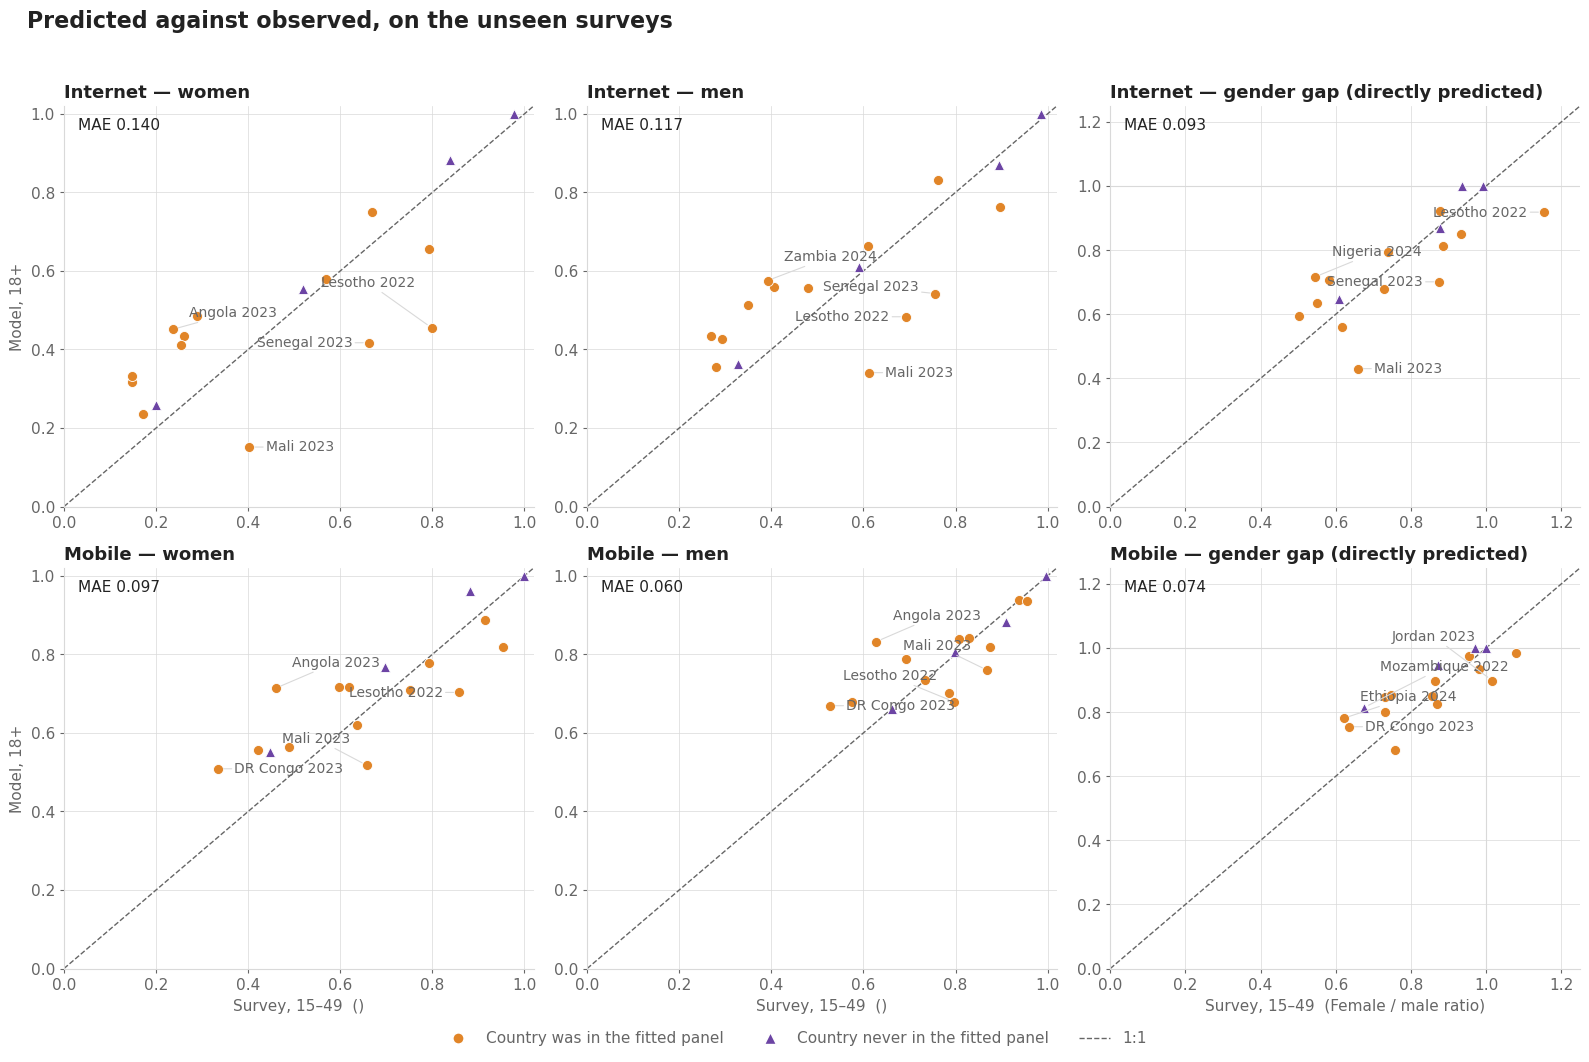

In [3]:
N_LABEL = 4   # largest |error| named per panel

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))

PANELS = [('level_women', 'women', '', (0, 1.02)),
          ('level_men', 'men', '', (0, 1.02)),
          ('ggi', f'gender gap ({GGI_LABEL})', 'Female / male ratio', (0, 1.25))]

for row, indicator in enumerate(INDICATORS):
    block = unseen[unseen['indicator'] == indicator]
    for col, (key, title, lab, lim) in enumerate(PANELS):
        ax = axes[row, col]
        if key == 'ggi':
            obs, pred = block['observed'], block[f'predicted_{GGI_DEFINITION}']
            ax.axhline(1.0, color=GRID, linewidth=0.8, zorder=0)
            ax.axvline(1.0, color=GRID, linewidth=0.8, zorder=0)
        else:
            obs, pred = block[f'observed_{key}'], block[f'predicted_{key}']

        ax.plot(lim, lim, ls='--', color=MUTED, linewidth=1, zorder=1)
        for seen, colour, marker in ((True, PRED_COLOUR, 'o'), (False, NEW_COUNTRY_INK, '^')):
            m = (block['country_in_training'] == seen).to_numpy()
            ax.scatter(obs[m], pred[m], s=52, marker=marker, color=colour,
                       edgecolor='white', linewidth=0.6, zorder=3)

        # Name only the biggest misses. Labels are placed beside the point, then pushed apart
        # vertically until none overlap, with a hairline back to the point they belong to —
        # a fixed offset put them on top of each other and on top of other points.
        err = (pred - obs).abs()
        worst = list(err.nlargest(N_LABEL).index)
        span = lim[1] - lim[0]
        gap, dx = 0.075 * span, 0.035 * span
        placed = -np.inf
        for idx in sorted(worst, key=lambda j: pred[j]):
            ly = max(pred[idx], placed + gap)
            right = obs[idx] < lim[0] + 0.62 * span      # flip inwards near the right edge
            ax.annotate(f"{block.loc[idx, 'country']} {int(block.loc[idx, 'year'])}",
                        xy=(obs[idx], pred[idx]),
                        xytext=(obs[idx] + (dx if right else -dx), ly),
                        ha='left' if right else 'right', va='center',
                        fontsize=STYLE['tick_fs'] - 1, color=MUTED,
                        arrowprops=dict(arrowstyle='-', color=GRID, linewidth=0.8,
                                        shrinkA=0, shrinkB=4))
            placed = ly

        mae = err.mean()
        ax.text(0.03, 0.97, f'MAE {mae:.3f}', transform=ax.transAxes, va='top', ha='left',
                fontsize=STYLE['tick_fs'], color=INK)

        tidy(ax, title=f'{indicator.capitalize()} — {title}')
        ax.set_xlim(*lim); ax.set_ylim(*lim)
        ax.grid(color=GRID, linewidth=0.5)
        ax.set_axisbelow(True)
        if row == 1:
            ax.set_xlabel(f'Survey, 15–49  ({lab})', fontsize=STYLE['tick_fs'], color=MUTED)
        if col == 0:
            ax.set_ylabel('Model, 18+', fontsize=STYLE['tick_fs'], color=MUTED)

handles = [plt.Line2D([], [], marker='o', linestyle='None', markersize=8,
                      markerfacecolor=PRED_COLOUR, markeredgecolor='white',
                      label='Country was in the fitted panel'),
           plt.Line2D([], [], marker='^', linestyle='None', markersize=8,
                      markerfacecolor=NEW_COUNTRY_INK, markeredgecolor='white',
                      label='Country never in the fitted panel'),
           plt.Line2D([], [], ls='--', color=MUTED, linewidth=1, label='1:1')]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Predicted against observed, on the unseen surveys',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0.01, 1, 0.96))
if STYLE['save']:
    fig.savefig(FIGDIR / '1_unseen_scatter.png', dpi=STYLE['dpi'], bbox_inches='tight')
plt.show()


### The same picture, with the fitted sample behind it

The panel above shows only the 17 unseen surveys, which makes them look worse or better than they
are — there is nothing to compare against. This puts the **whole sample the models were fitted on**
behind them in green, so the unseen points can be read against the cloud the model was built to
reproduce.

**Ground truth on the x-axis means the panel's own outcome**, taken from the fitting panel rather
than from `update_full_groundtruth`. That is what lets the ITU rows appear: they are a third of the
training sample but carry no DHS/MICS microdata, so the survey file excludes them and an earlier
version of this chart silently dropped them.

| | internet | mobile |
| --- | --- | --- |
| fitted, survey-measured | 71 | 75 |
| fitted, ITU-reported | 36 | 24 |
| unseen surveys | 17 | 17 |

Internet is 107 fitted rows, not 108: Kosovo 2018 (an ITU row) has no coherent-GGI prediction.
Mobile counts *rows*, so GIN 2018, TGO 2017 and ZMB 2018 each contribute two points — they are
duplicated in the shipped panel with conflicting values, the still-open defect from D28.

**ITU rows are drawn hollow** because they are a different measurement instrument from a household
survey, and they behave differently: they sit in the high-adoption corner and fit far better than
the survey rows. Read the two green groups separately, not as one cloud.

**These are the original models**, not the extended panel from
`13_extended_panel_exploration.ipynb`: notebook 02 scores the stored fitting panel and the published
coherent-GGI series, neither of which is rebuilt from `params.OFFLINE_PREDICTORS`. So the green
cloud is the fit as published, and adding the surveys has not been allowed to move it.


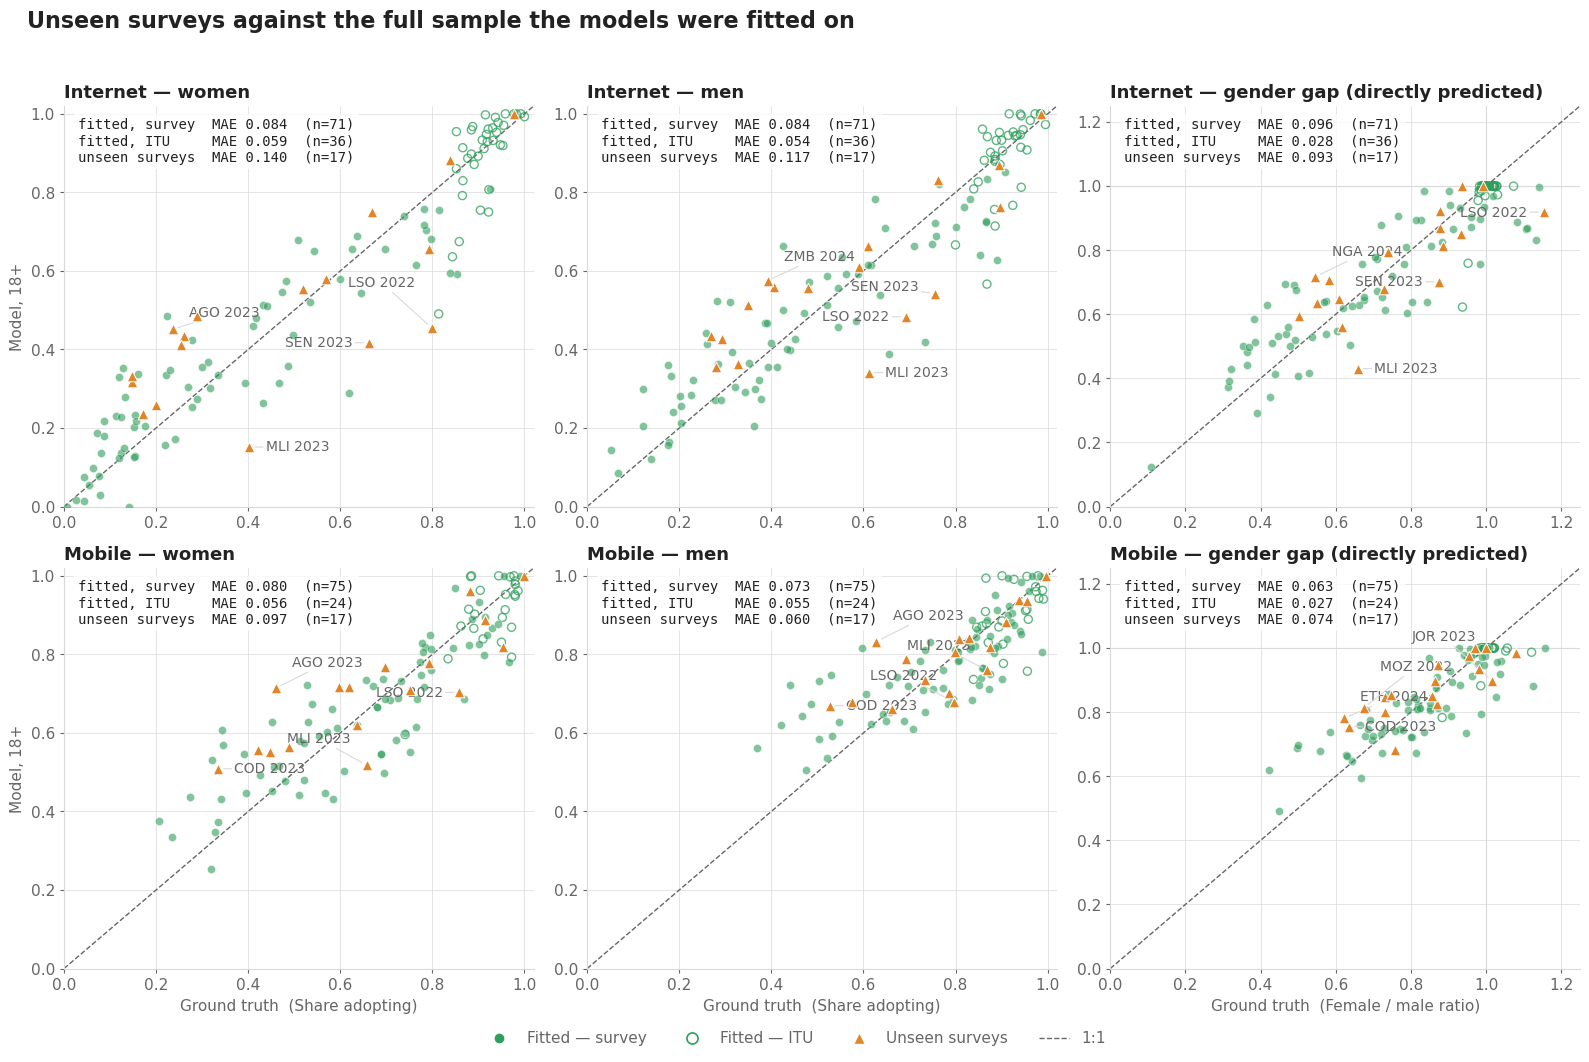

In [4]:
TRAIN_COLOUR = '#2E9E5B'   # green, reserved here for the fitted sample

# The fitted cloud is built from the FITTING PANEL itself, not from update_full_groundtruth.
# That matters: the panel is the ground truth the models were actually fitted on, and it includes
# the ITU rows (37 internet, 24 mobile) that update_full_groundtruth filters out. Taking the
# observed values from the panel puts every training observation on the chart — survey-measured
# and ITU-reported alike — which is what "x-axis = ground truth" means here.
GGI_COL = {'direct': '{ind}_ggi_direct',
           'coherent_parity': '{ind}_ggi_coherent_mean_of_ratios',
           'coherent_raw': '{ind}_ggi_coherent_mean_of_ratios_raw'}[GGI_DEFINITION]

coherent = pd.read_csv(sorted(params.table_dir('04_coherent_ggi_figures')
                              .glob('coherent_ggi_country_year_*.csv'))[-1])


def fitted_panel(indicator):
    """
    the fitting panel with its own outcomes, joined to the model's predictions

    Prediction columns are renamed to a `pred_` prefix before merging: `{ind}_men` names the
    OBSERVED men's level in the panel and the PREDICTED one in the coherent series, and a merge
    that lets them collide reads as perfect agreement.
    """
    panel = pd.read_csv(params.PROCESSED / 'combined_data/updated_ground_truth_and_fb'
                        / indicator / params.FINAL_MODEL['dataset'])
    panel['year'] = panel[f'{indicator}_year'].astype(int)
    pred = coherent[['gid_0', 'year', f'{indicator}_women', f'{indicator}_men',
                     GGI_COL.format(ind=indicator)]].rename(columns={
                         f'{indicator}_women': 'pred_wom',
                         f'{indicator}_men': 'pred_men',
                         GGI_COL.format(ind=indicator): 'pred_ggi'})
    merged = panel.merge(pred, left_on=['iso3', 'year'], right_on=['gid_0', 'year'], how='left')
    merged['is_itu'] = (merged[f'{indicator}_survey_type'].astype(str)
                        .str.contains('itu', case=False, na=False))
    return merged


# observed column in the panel -> predicted column in the coherent series
PANELS = [('wom', 'pred_wom', 'women', 'Share adopting', (0, 1.02)),
          ('men', 'pred_men', 'men', 'Share adopting', (0, 1.02)),
          ('ggi', 'pred_ggi', f'gender gap ({GGI_LABEL})', 'Female / male ratio', (0, 1.25))]

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))

for row, indicator in enumerate(INDICATORS):
    train = fitted_panel(indicator)
    for col, (obs_stem, pred_col, title, lab, lim) in enumerate(PANELS):
        ax = axes[row, col]
        obs_col = f'{indicator}_{obs_stem}'

        block = train.dropna(subset=[obs_col, pred_col])
        survey, itu = block[~block['is_itu']], block[block['is_itu']]

        if obs_stem == 'ggi':
            held = gt[(gt['indicator'] == indicator) & (gt['definition'] == GGI_DEFINITION)
                      & (~gt['in_training'])]
        else:
            sex = 'women' if obs_stem == 'wom' else 'men'
            held = levels[(levels['indicator'] == indicator) & (levels['sex'] == sex)
                          & (~levels['in_training'])]

        ax.plot(lim, lim, ls='--', color=MUTED, linewidth=1, zorder=1)
        if obs_stem == 'ggi':
            ax.axhline(1.0, color=GRID, linewidth=0.8, zorder=0)
            ax.axvline(1.0, color=GRID, linewidth=0.8, zorder=0)

        # ITU observations are a different instrument from a household survey, so they are drawn
        # hollow rather than merged invisibly into the survey cloud
        ax.scatter(itu[obs_col], itu[pred_col], s=34, marker='o', facecolor='none',
                   edgecolor=TRAIN_COLOUR, linewidth=1.0, alpha=0.75, zorder=2)
        ax.scatter(survey[obs_col], survey[pred_col], s=34, marker='o', color=TRAIN_COLOUR,
                   alpha=0.6, edgecolor='white', linewidth=0.4, zorder=3)
        ax.scatter(held['observed'], held['predicted'], s=58, marker='^',
                   color=PRED_COLOUR, edgecolor='white', linewidth=0.7, zorder=4)

        # name the biggest misses among the UNSEEN points only, de-collided vertically
        span = lim[1] - lim[0]
        gap, dx = 0.075 * span, 0.035 * span
        err = (held['predicted'] - held['observed']).abs()
        placed = -np.inf
        for idx in err.nlargest(N_LABEL).index.sort_values(key=lambda i: held['predicted'][i]):
            ly = max(held['predicted'][idx], placed + gap)
            right = held['observed'][idx] < lim[0] + 0.62 * span
            ax.annotate(f"{held['gid_0'][idx]} {int(held['year'][idx])}",
                        xy=(held['observed'][idx], held['predicted'][idx]),
                        xytext=(held['observed'][idx] + (dx if right else -dx), ly),
                        ha='left' if right else 'right', va='center',
                        fontsize=STYLE['tick_fs'] - 1, color=MUTED,
                        arrowprops=dict(arrowstyle='-', color=GRID, linewidth=0.8,
                                        shrinkA=0, shrinkB=4))
            placed = ly

        mae = lambda d, o, p: (d[p] - d[o]).abs().mean()
        ax.text(0.03, 0.97,
                f'fitted, survey  MAE {mae(survey, obs_col, pred_col):.3f}  (n={len(survey)})\n'
                f'fitted, ITU     MAE {mae(itu, obs_col, pred_col):.3f}  (n={len(itu)})\n'
                f'unseen surveys  MAE {(held["predicted"] - held["observed"]).abs().mean():.3f}'
                f'  (n={len(held)})',
                transform=ax.transAxes, va='top', ha='left', family='monospace',
                fontsize=STYLE['tick_fs'] - 1, color=INK,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=3))

        tidy(ax, title=f'{indicator.capitalize()} — {title}')
        ax.set_xlim(*lim); ax.set_ylim(*lim)
        ax.grid(color=GRID, linewidth=0.5)
        ax.set_axisbelow(True)
        if row == 1:
            ax.set_xlabel(f'Ground truth  ({lab})', fontsize=STYLE['tick_fs'], color=MUTED)
        if col == 0:
            ax.set_ylabel('Model, 18+', fontsize=STYLE['tick_fs'], color=MUTED)

handles = [plt.Line2D([], [], marker='o', linestyle='None', markersize=8,
                      markerfacecolor=TRAIN_COLOUR, markeredgecolor='white',
                      label='Fitted — survey'),
           plt.Line2D([], [], marker='o', linestyle='None', markersize=8,
                      markerfacecolor='none', markeredgecolor=TRAIN_COLOUR, markeredgewidth=1.2,
                      label='Fitted — ITU'),
           plt.Line2D([], [], marker='^', linestyle='None', markersize=8,
                      markerfacecolor=PRED_COLOUR, markeredgecolor='white',
                      label='Unseen surveys'),
           plt.Line2D([], [], ls='--', color=MUTED, linewidth=1, label='1:1')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Unseen surveys against the full sample the models were fitted on',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0.01, 1, 0.96))
if STYLE['save']:
    fig.savefig(FIGDIR / '1b_unseen_vs_fitted_scatter.png', dpi=STYLE['dpi'], bbox_inches='tight')
plt.show()


### Countries the models had already seen — do they track over time?

The held-out surveys split sharply on whether the model had ever seen that country:

| | n | MAE | bias |
| --- | --- | --- | --- |
| internet, **country seen before** | 13 | **0.113** | −0.025 |
| internet, country never seen | 4 | **0.029** | +0.025 |
| mobile, **country seen before** | 13 | 0.077 | +0.018 |
| mobile, country never seen | 4 | 0.061 | +0.061 |

That is backwards from the obvious expectation — a country the model has already fitted should be
*easier*, not four times harder. So it is worth looking at these countries individually rather than
as an average.

Each of the 13 has two to four surveys. The panels below draw every one of them: the ground truth
against the model's prediction, year by year, with the **held-out year ringed**. The question is
not whether the level is right but whether the model tracks the country's *movement* — it was
fitted on the earlier point, so the later one is a genuine forecast.

(The four never-seen countries — MOZ, NRU, QAT, VUT — have a single survey each and no trajectory
to draw. Their low error is on four points and should not be read as skill; see D36.)

**What the panels show, and it is not what the split implied.** Median |error| **at the year the
model was fitted on is 0.080; at the held-out year it is 0.085** — essentially the same number, and
the direction of change is right in 10 of 13. The held-out miss is overwhelmingly an **old level
error carried forward**, not a failure to forecast: Lesotho is 0.24 low in 2018 and 0.24 low in
2022; Mali is low at both ends; Senegal's predicted series is nearly flat while the survey climbs.

So "countries seen before are worse" does not mean prediction decays with time. It means those
countries were **already poorly fitted**, and the same offset reappears. The never-seen four score
better because they happen to be easy — high adoption, near parity — not because unseen-ness helps.
The out-of-sample cost proper is the difference between the two medians: about **0.005**.


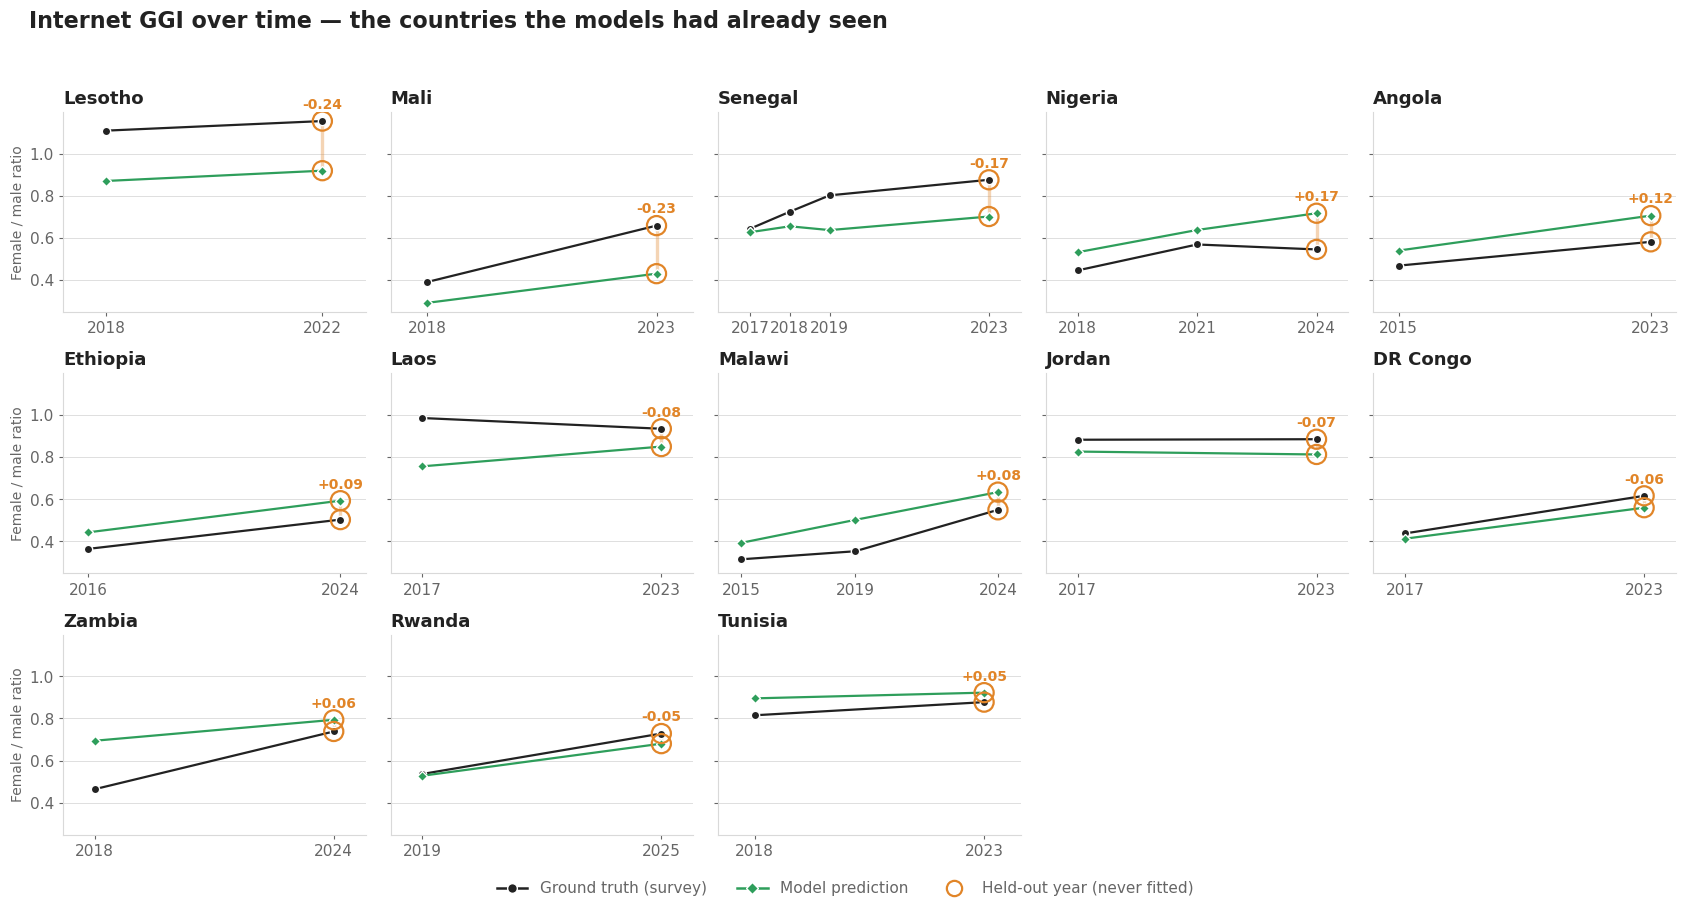

In [5]:
# Which series to draw. The GGI is the published outcome, so it leads; switch to a level to see
# where a gap error comes from.
TRAJECTORY_INDICATOR = 'internet'
TRAJECTORY_OUTCOME = 'ggi'          # 'ggi' | 'wom' | 'men'

if TRAJECTORY_OUTCOME == 'ggi':
    series = gt[(gt['indicator'] == TRAJECTORY_INDICATOR)
                & (gt['definition'] == GGI_DEFINITION)].copy()
    ylabel = 'Female / male ratio'
else:
    sex = 'women' if TRAJECTORY_OUTCOME == 'wom' else 'men'
    series = levels[(levels['indicator'] == TRAJECTORY_INDICATOR)
                    & (levels['sex'] == sex)].copy()
    ylabel = f'Share adopting ({sex})'

# countries with a held-out survey AND at least one the model was fitted on
repeat = sorted(c for c in series.loc[~series['in_training'], 'gid_0'].unique()
                if series[(series['gid_0'] == c) & series['in_training']].shape[0] > 0)

# worst held-out miss first — the interesting cases should not be buried mid-grid
order = (series[~series['in_training'] & series['gid_0'].isin(repeat)]
         .assign(abs_err=lambda d: (d['predicted'] - d['observed']).abs())
         .sort_values('abs_err', ascending=False)['gid_0'].tolist())

ncol = 5
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.0 * nrow), sharey=True)

for ax, iso in zip(axes.ravel(), order):
    block = series[series['gid_0'] == iso].sort_values('year')
    yrs = block['year'].astype(int)

    ax.plot(yrs, block['observed'], color=INK, linewidth=1.6, marker='o', markersize=6,
            markerfacecolor=INK, markeredgecolor='white', zorder=3, label='Ground truth')
    ax.plot(yrs, block['predicted'], color=TRAIN_COLOUR, linewidth=1.6, marker='D',
            markersize=5.5, markerfacecolor=TRAIN_COLOUR, markeredgecolor='white',
            zorder=3, label='Model')

    # the held-out year: ring both marks and shade the miss between them
    held = block[~block['in_training']]
    for _, r in held.iterrows():
        ax.scatter([r['year']] * 2, [r['observed'], r['predicted']], s=190, facecolors='none',
                   edgecolor=PRED_COLOUR, linewidth=1.6, zorder=4)
        ax.vlines(r['year'], min(r['observed'], r['predicted']),
                  max(r['observed'], r['predicted']), color=PRED_COLOUR, linewidth=2.4,
                  alpha=0.35, zorder=2)
        ax.annotate(f"{r['predicted'] - r['observed']:+.2f}",
                    (r['year'], max(r['observed'], r['predicted'])),
                    textcoords='offset points', xytext=(0, 9), ha='center',
                    fontsize=STYLE['tick_fs'] - 1, color=PRED_COLOUR, fontweight='bold')

    ax.set_xticks(list(yrs))
    ax.set_xticklabels([str(y) for y in yrs], fontsize=STYLE['tick_fs'] - 2)
    ax.set_xlim(yrs.min() - 0.8, yrs.max() + 0.8)
    tidy(ax, title=f"{block['country'].iloc[0]}")
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

for ax in axes.ravel()[len(order):]:
    ax.set_visible(False)

for r in range(nrow):
    axes[r, 0].set_ylabel(ylabel, fontsize=STYLE['tick_fs'] - 1, color=MUTED)

handles = [plt.Line2D([], [], color=INK, linewidth=1.8, marker='o', markersize=7,
                      markeredgecolor='white', label='Ground truth (survey)'),
           plt.Line2D([], [], color=TRAIN_COLOUR, linewidth=1.8, marker='D', markersize=6,
                      markeredgecolor='white', label='Model prediction'),
           plt.Line2D([], [], marker='o', linestyle='None', markersize=11, markerfacecolor='none',
                      markeredgecolor=PRED_COLOUR, markeredgewidth=1.6,
                      label='Held-out year (never fitted)')]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(f'{TRAJECTORY_INDICATOR.capitalize()} {TRAJECTORY_OUTCOME.upper()} over time — '
             'the countries the models had already seen',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
if STYLE['save']:
    fig.savefig(FIGDIR / f'1c_repeat_country_trajectories_'
                         f'{TRAJECTORY_INDICATOR}_{TRAJECTORY_OUTCOME}.png',
                dpi=STYLE['dpi'], bbox_inches='tight')
plt.show()


In [6]:
# Is the held-out miss NEW, or was the model already off at the fitted year? And does it get the
# DIRECTION of change right? Those are different failures and they need different fixes.
rows = []
for iso in order:
    b = series[series['gid_0'] == iso].sort_values('year')
    fitted, held = b[b['in_training']], b[~b['in_training']]
    if fitted.empty or held.empty:
        continue
    last_fit, hold = fitted.iloc[-1], held.iloc[-1]
    obs_change = hold['observed'] - last_fit['observed']
    pred_change = hold['predicted'] - last_fit['predicted']
    rows.append({
        'country': b['country'].iloc[0], 'iso3': iso,
        'fitted_year': int(last_fit['year']), 'held_year': int(hold['year']),
        'err_at_fitted': last_fit['predicted'] - last_fit['observed'],
        'err_at_held': hold['predicted'] - hold['observed'],
        'observed_change': obs_change, 'predicted_change': pred_change,
        'direction_ok': np.sign(obs_change) == np.sign(pred_change),
    })

diagnosis = pd.DataFrame(rows)
diagnosis['carried_over'] = (diagnosis['err_at_fitted'].abs()
                             / diagnosis['err_at_held'].abs().replace(0, np.nan))

print(f"direction of change predicted correctly: "
      f"{int(diagnosis['direction_ok'].sum())} of {len(diagnosis)}")
print(f"median |error| already present at the fitted year : "
      f"{diagnosis['err_at_fitted'].abs().median():.3f}")
print(f"median |error| at the held-out year              : "
      f"{diagnosis['err_at_held'].abs().median():.3f}")
print("\n-> where the two are similar, the held-out miss is an OLD level error carried forward,")
print("   not a failure to forecast. Where they differ, the model mis-tracked the change.")

diagnosis.sort_values('err_at_held', key=abs, ascending=False).round(3).reset_index(drop=True)


direction of change predicted correctly: 10 of 13
median |error| already present at the fitted year : 0.080
median |error| at the held-out year              : 0.085

-> where the two are similar, the held-out miss is an OLD level error carried forward,
   not a failure to forecast. Where they differ, the model mis-tracked the change.


,country,iso3,fitted_year,held_year,err_at_fitted,err_at_held,observed_change,predicted_change,direction_ok,carried_over
0,Lesotho,LSO,2018,2022,-0.239,-0.235,0.045,0.049,True,1.014
1,Mali,MLI,2018,2023,-0.099,-0.228,0.267,0.138,True,0.434
2,Senegal,SEN,2019,2023,-0.165,-0.174,0.074,0.064,True,0.945
3,Nigeria,NGA,2021,2024,0.069,0.172,-0.023,0.079,False,0.400
4,Angola,AGO,2015,2023,0.072,0.124,0.113,0.166,True,0.575
5,Ethiopia,ETH,2016,2024,0.078,0.090,0.139,0.150,True,0.873
6,Laos,LAO,2017,2023,-0.229,-0.085,-0.051,0.094,False,2.710
7,Malawi,MWI,2019,2024,0.149,0.084,0.196,0.132,True,1.770
8,Jordan,JOR,2017,2023,-0.056,-0.072,0.002,-0.014,False,0.776
9,DR Congo,COD,2017,2023,-0.025,-0.056,0.178,0.147,True,0.442


### Accuracy metrics

The three quantities in the figure above — the two adoption levels and the gender gap built from
them — scored against the survey. The GGI bar uses the same `GGI_DEFINITION` as the third column,
so the panel is internally consistent; all three definitions are compared in `09_01` section G.

`METRIC` in the setup cell switches the bar between `'mae'`, `'rmse'` and `'r2'`. They are not
interchangeable: MAE is the average miss in the outcome's own units, R² is whether the model beats
predicting the sample mean, measured against the 1:1 line so it charges for bias as well as
scatter. A sample can look strong on one and weak on the other — mobile's four new countries reach
`pearson_r` 0.99 and R² 0.50, which is exactly that gap.

`held_out` is the 17 unseen surveys; `held_out, new country` is the 4 whose country the models had
never seen. Four points is an illustration, not a statistic, so `n` is printed on every bar.


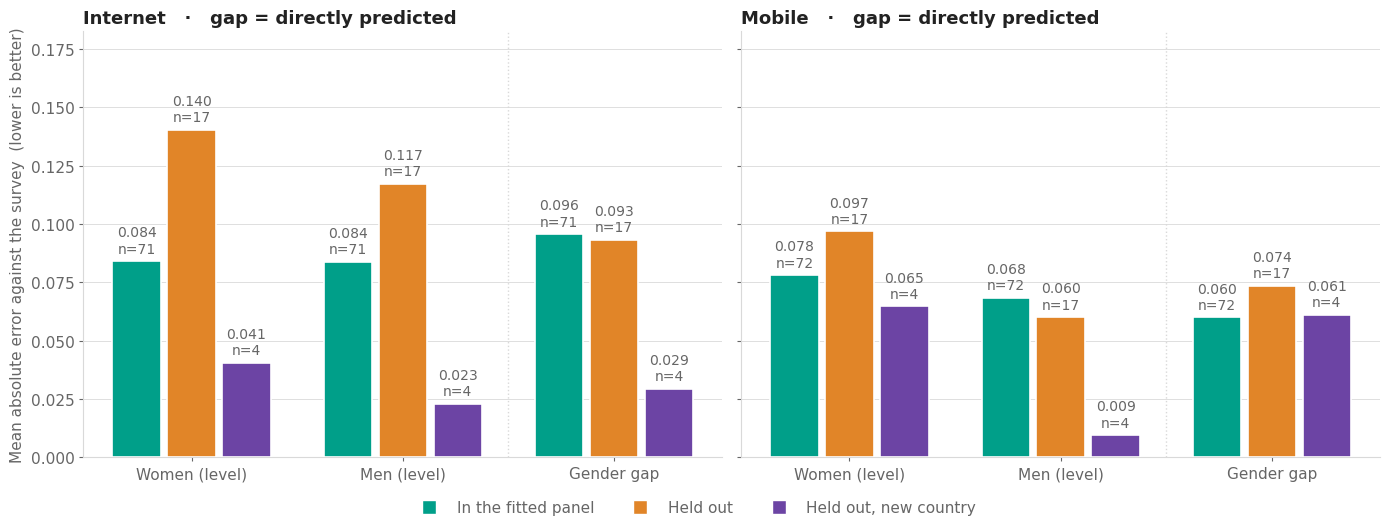

,indicator,sex,sample,n,bias,mae,rmse,r2,within_0.05,within_0.10,pearson_r,spearman_r
1,internet,men,in_training,71,0.0033,0.0838,0.1104,0.7758,36.6197,74.6479,0.8822,0.8801
2,internet,men,held_out,17,0.0172,0.1172,0.1396,0.6317,23.5294,47.0588,0.7983,0.7034
3,internet,men,held_out_new_country,4,0.0108,0.0229,0.0240,0.9914,100.0000,100.0000,0.9979,1.0000
5,internet,women,in_training,71,0.0082,0.0840,0.1098,0.8167,36.6197,64.7887,0.9051,0.9028
6,internet,women,held_out,17,0.0256,0.1404,0.1680,0.6144,23.5294,41.1765,0.7899,0.7892
7,internet,women,held_out_new_country,4,0.0406,0.0406,0.0426,0.9799,75.0000,100.0000,0.9997,1.0000
9,mobile,men,in_training,72,-0.0013,0.0684,0.0905,0.6347,43.0556,79.1667,0.7973,0.8095
10,mobile,men,held_out,17,0.0114,0.0600,0.0843,0.5865,52.9412,70.5882,0.7708,0.8039
11,mobile,men,held_out_new_country,4,-0.0042,0.0094,0.0137,0.9879,100.0000,100.0000,0.9946,1.0000
13,mobile,women,in_training,72,0.0024,0.0780,0.1007,0.7503,44.4444,70.8333,0.8667,0.8845


,indicator,definition,sample,n_dropped_zero_floor,n,bias,mae,rmse,r2,within_0.05,within_0.10,pearson_r,spearman_r
1,internet,coherent_parity,in_training,0,71,0.0153,0.1163,0.1511,0.6076,28.1690,53.5211,0.8036,0.8503
2,internet,coherent_parity,held_out,0,17,0.0446,0.1174,0.1439,0.3816,29.4118,47.0588,0.6659,0.8056
3,internet,coherent_parity,held_out_new_country,0,4,0.0529,0.0529,0.0641,0.8087,50.0000,75.0000,0.9886,0.9487
5,internet,coherent_raw,in_training,0,71,0.0159,0.1157,0.1507,0.6101,28.1690,54.9296,0.8057,0.8503
6,internet,coherent_raw,held_out,0,17,0.0454,0.1182,0.1442,0.3786,29.4118,47.0588,0.6656,0.8039
7,internet,coherent_raw,held_out_new_country,0,4,0.0560,0.0560,0.0674,0.7884,50.0000,75.0000,0.9818,0.8000
9,internet,direct,in_training,0,71,-0.0004,0.0956,0.1179,0.7614,29.5775,64.7887,0.8748,0.8651
10,internet,direct,held_out,0,17,-0.0135,0.0933,0.1153,0.6025,29.4118,70.5882,0.7825,0.7885
11,internet,direct,held_out_new_country,0,4,0.0248,0.0293,0.0371,0.9359,75.0000,100.0000,0.9821,0.9487
13,mobile,coherent_parity,in_training,0,72,0.0049,0.0579,0.0830,0.7214,61.1111,80.5556,0.8519,0.8589


In [7]:
SAMPLES = [('in_training', 'In the fitted panel'),
           ('held_out', 'Held out'),
           ('held_out_new_country', 'Held out, new country')]
SAMPLE_COLOUR = dict(zip([k for k, _ in SAMPLES], PALETTE[:3]))
SAMPLE_KEYS = [k for k, _ in SAMPLES]

# Levels and the gap in one frame: same metric, same samples, so they belong on one axis. The GGI
# rows are filtered to GGI_DEFINITION, matching the third column of the figure above.
metrics = pd.concat([
    (level_stats[level_stats['sample'].isin(SAMPLE_KEYS)]
     .assign(quantity=lambda d: d['sex'].str.capitalize() + ' (level)')),
    (gt_stats[(gt_stats['sample'].isin(SAMPLE_KEYS))
              & (gt_stats['definition'] == GGI_DEFINITION)]
     .assign(quantity='Gender gap')),
], ignore_index=True)

QUANTITIES = ['Women (level)', 'Men (level)', 'Gender gap']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)

# The axes share y, so the limit has to come from BOTH panels: taking it per-panel let the second
# one win and clipped the tallest bar's label off the top.
vals_all = metrics[METRIC]
YMIN = min(0.0, vals_all.min() * 1.25)
YMAX = vals_all.max() * 1.30 if vals_all.max() > 0 else 0.05

for ax, indicator in zip(axes, INDICATORS):
    block = metrics[metrics['indicator'] == indicator]
    x = np.arange(len(QUANTITIES))
    width = 0.26

    for k, (key, label) in enumerate(SAMPLES):
        vals, ns = [], []
        for q in QUANTITIES:
            row = block[(block['quantity'] == q) & (block['sample'] == key)]
            vals.append(float(row[METRIC].squeeze()) if len(row) else np.nan)
            ns.append(int(row['n'].squeeze()) if len(row) else 0)
        pos = x + (k - 1) * width
        ax.bar(pos, vals, width * 0.88, color=SAMPLE_COLOUR[key],
               edgecolor='white', linewidth=1.2, zorder=3)
        for pp, v, n in zip(pos, vals, ns):
            # labels go above a positive bar and below a negative one (R2 can be < 0)
            above = v >= 0
            ax.annotate(METRIC_SPEC['fmt'].format(v) + f'\nn={n}', (pp, v),
                        textcoords='offset points', xytext=(0, 4 if above else -4),
                        ha='center', va='bottom' if above else 'top',
                        fontsize=STYLE['tick_fs'] - 1, color=MUTED)

    # the gap is a different kind of quantity from a level; mark the boundary rather than imply
    # the three bars are three of a kind
    ax.axvline(1.5, color=GRID, linewidth=1, linestyle=':', zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(QUANTITIES)
    ax.set_ylim(YMIN, YMAX)
    if YMIN < 0:
        ax.axhline(0, color=MUTED, linewidth=1, zorder=2)
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    tidy(ax, title=f'{indicator.capitalize()}   ·   gap = {GGI_LABEL}')

direction = 'higher is better' if METRIC_SPEC['higher_is_better'] else 'lower is better'
axes[0].set_ylabel(f"{METRIC_SPEC['label']}  ({direction})",
                   fontsize=STYLE['tick_fs'], color=MUTED)
handles = [plt.Line2D([], [], marker='s', linestyle='None', markersize=10,
                      markerfacecolor=SAMPLE_COLOUR[k], markeredgecolor='white', label=lab)
           for k, lab in SAMPLES]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.06))
#fig.suptitle('Accuracy on levels and on the gap, by sample', fontsize=STYLE['title_fs'],
#             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.93))
if STYLE['save']:
    fig.savefig(FIGDIR / '2_accuracy_metrics.png', dpi=STYLE['dpi'], bbox_inches='tight')
plt.show()

display(level_stats[level_stats['sample'].isin(SAMPLE_KEYS)].round(4))
gt_stats[gt_stats['sample'].isin(SAMPLE_KEYS)].round(4)


## 3. The gender gap on the unseen surveys

The ratio of the two levels above, for every survey. Two model definitions against the one
observation — the directly predicted GGI and the project's primary coherent (parity-capped) one.
`09_01` section G takes the choice between definitions further.

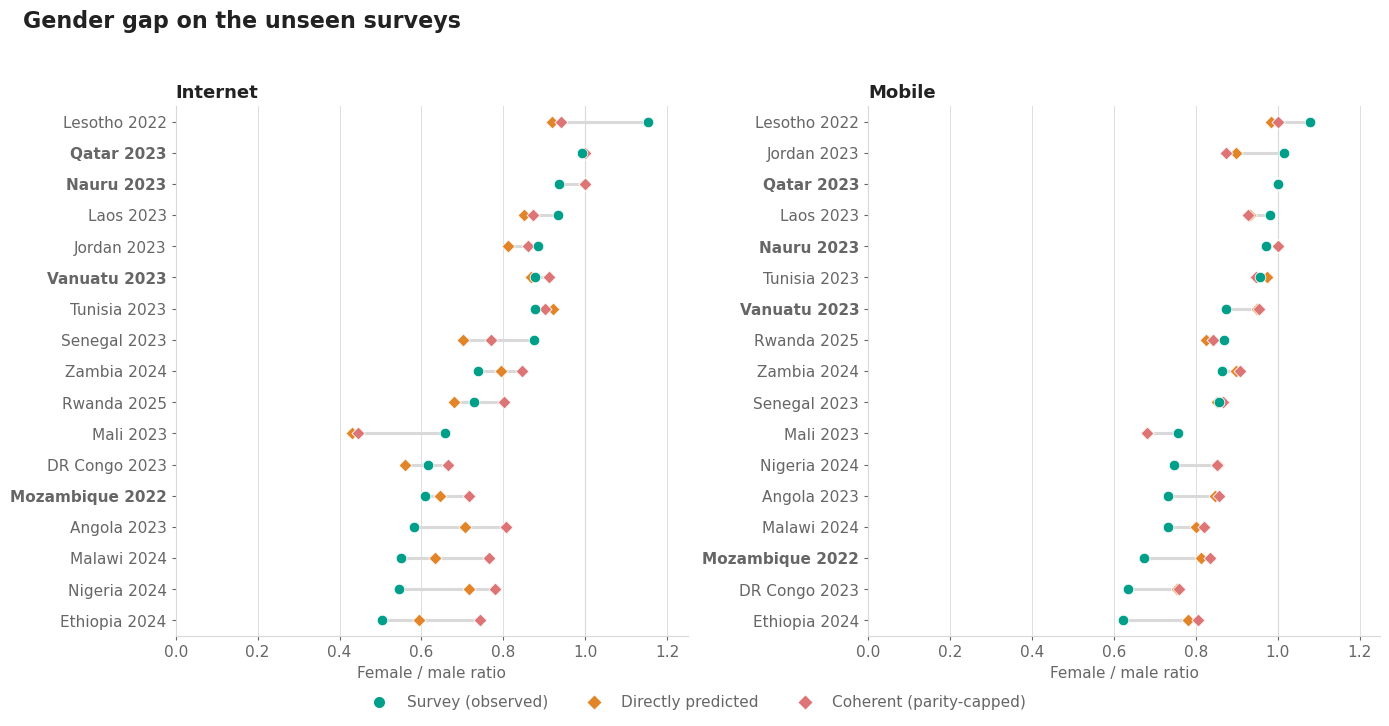

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True)

# Survey, direct and parity-capped coherent only. The raw coherent GGI is identical to the capped
# one except where it exceeds parity, so plotting it here adds a mark that is almost always hidden
# behind another; it is compared properly in 09_01 section G.
DEFS = [('direct', 'Directly predicted', PALETTE[1]),
        ('coherent_parity', 'Coherent (parity-capped)', PALETTE[3])]

for ax, indicator in zip(axes, INDICATORS):
    block = (unseen[unseen['indicator'] == indicator]
             .sort_values('observed', ascending=False).reset_index(drop=True))
    y = np.arange(len(block))

    lo = block[['observed'] + [f'predicted_{d}' for d, _, _ in DEFS]].min(axis=1)
    hi = block[['observed'] + [f'predicted_{d}' for d, _, _ in DEFS]].max(axis=1)
    ax.hlines(y, lo, hi, color=GRID, linewidth=2.2, zorder=1)

    for d, _, colour in DEFS:
        ax.scatter(block[f'predicted_{d}'], y, s=44, marker=PRED_MARKER, color=colour,
                   edgecolor='white', linewidth=0.6, zorder=3)
    ax.scatter(block['observed'], y, s=58, marker=OBS_MARKER, color=OBS_COLOUR,
               edgecolor='white', linewidth=0.6, zorder=4)
    ax.axvline(1.0, color=GRID, linewidth=0.8, zorder=0)

    ax.set_yticks(y)
    ax.set_yticklabels([f"{c} {int(yr)}" for c, yr in zip(block['country'], block['year'])])
    for tick, seen in zip(ax.get_yticklabels(), block['country_in_training']):
        if not seen:
            tick.set_color(NEW_COUNTRY_INK)
            tick.set_fontweight('bold')
    ax.set_ylim(len(block) - 0.5, -0.5)
    ax.grid(axis='x', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    tidy(ax, title=indicator.capitalize(), xlabel='Female / male ratio')
    ax.set_xlim(0, 1.25)

handles = ([plt.Line2D([], [], marker=OBS_MARKER, linestyle='None', markersize=9,
                       markerfacecolor=OBS_COLOUR, markeredgecolor='white',
                       label='Survey (observed)')]
           + [plt.Line2D([], [], marker=PRED_MARKER, linestyle='None', markersize=8,
                         markerfacecolor=c, markeredgecolor='white', label=lab)
              for _, lab, c in DEFS])
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Gender gap on the unseen surveys', fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.95))
if STYLE['save']:
    fig.savefig(FIGDIR / '3_unseen_ggi.png', dpi=STYLE['dpi'], bbox_inches='tight')
plt.show()

## 4. Signed error, worst first

Positive means the model sits **above** the survey. The direction matters more than the magnitude
here: a systematic sign is a bias the models could be corrected for, scatter around zero is not.

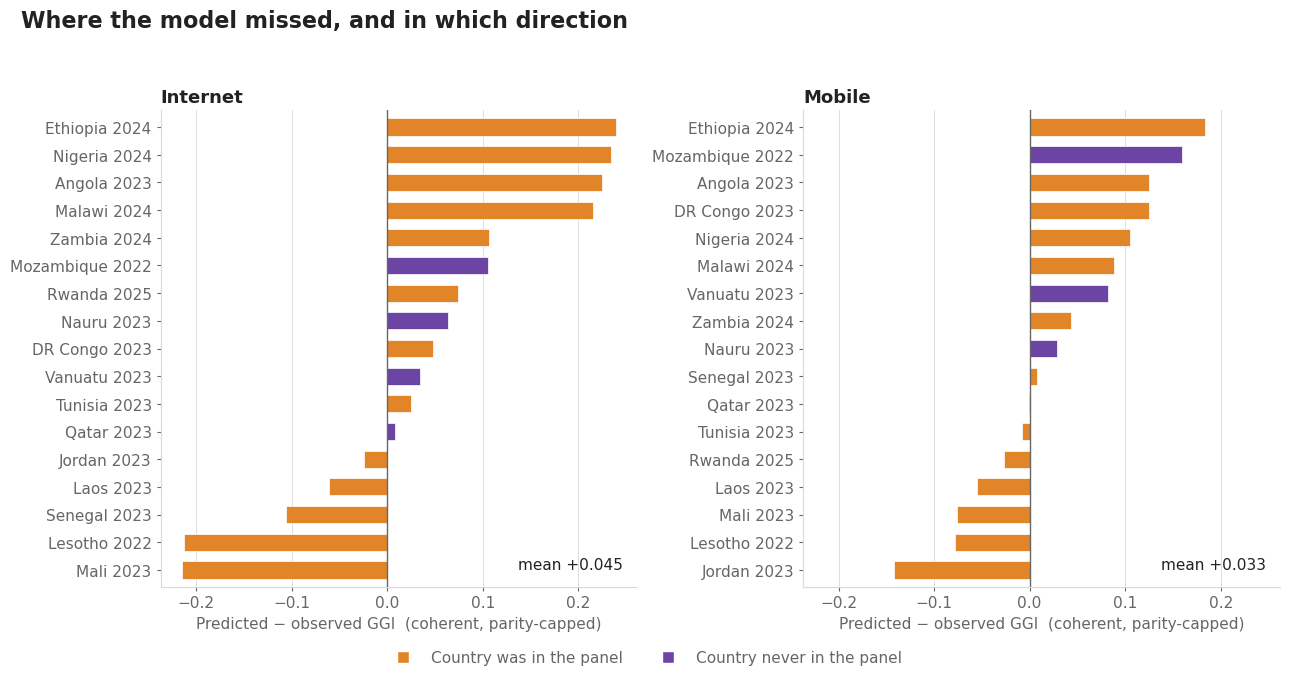

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharex=True)

for ax, indicator in zip(axes, INDICATORS):
    block = (unseen[unseen['indicator'] == indicator]
             .assign(err=lambda d: d['error_coherent_parity'])
             .sort_values('err').reset_index(drop=True))
    y = np.arange(len(block))
    colours = [PRED_COLOUR if seen else NEW_COUNTRY_INK
               for seen in block['country_in_training']]
    ax.barh(y, block['err'], height=0.62, color=colours, edgecolor='white', linewidth=0.5)
    ax.axvline(0, color=MUTED, linewidth=1)

    ax.set_yticks(y)
    ax.set_yticklabels([f"{c} {int(yr)}" for c, yr in zip(block['country'], block['year'])])
    ax.set_ylim(-0.6, len(block) - 0.4)
    ax.grid(axis='x', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    bias = block['err'].mean()
    ax.text(0.97, 0.03, f'mean {bias:+.3f}', transform=ax.transAxes, ha='right', va='bottom',
            fontsize=STYLE['tick_fs'], color=INK)
    tidy(ax, title=indicator.capitalize(),
         xlabel='Predicted − observed GGI  (coherent, parity-capped)')

handles = [plt.Line2D([], [], marker='s', linestyle='None', markersize=9, markerfacecolor=c,
                      markeredgecolor='white', label=lab)
           for c, lab in ((PRED_COLOUR, 'Country was in the panel'),
                          (NEW_COUNTRY_INK, 'Country never in the panel'))]
fig.legend(handles=handles, loc='lower center', ncol=2, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.05))
fig.suptitle('Where the model missed, and in which direction', fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.94))
if STYLE['save']:
    fig.savefig(FIGDIR / '4_unseen_error.png', dpi=STYLE['dpi'], bbox_inches='tight')
plt.show()

## 5. Survey by survey

Everything above in one sheet, for reading individual cases.

In [10]:
cols = ['indicator', 'gid_0', 'country', 'year', 'survey_type', 'country_in_training',
        'observed_level_women', 'predicted_level_women',
        'observed_level_men', 'predicted_level_men',
        'observed', 'predicted_direct', 'predicted_coherent_raw', 'predicted_coherent_parity',
        'error_direct', 'error_coherent_raw', 'error_coherent_parity']
unseen[cols].round(4).reset_index(drop=True)

,indicator,gid_0,country,year,survey_type,country_in_training,observed_level_women,predicted_level_women,observed_level_men,predicted_level_men,observed,predicted_direct,predicted_coherent_raw,predicted_coherent_parity,error_direct,error_coherent_raw,error_coherent_parity
0,internet,LSO,Lesotho,2022,dhs8,True,0.7987,0.4549,0.6921,0.4833,1.1540,0.9187,0.9412,0.9412,-0.2353,-0.2128,-0.2128
1,internet,MOZ,Mozambique,2022,dhs8,False,0.2000,0.2591,0.3279,0.3620,0.6099,0.6465,0.7157,0.7157,0.0366,0.1058,0.1058
2,internet,AGO,Angola,2023,dhs8,True,0.2364,0.4513,0.4067,0.5598,0.5813,0.7056,0.8062,0.8062,0.1243,0.2249,0.2249
3,internet,COD,DR Congo,2023,dhs8,True,0.1725,0.2360,0.2799,0.3555,0.6163,0.5598,0.6638,0.6638,-0.0564,0.0476,0.0476
4,internet,JOR,Jordan,2023,dhs8,True,0.7926,0.6569,0.8961,0.7638,0.8846,0.8122,0.8601,0.8601,-0.0723,-0.0245,-0.0245
5,internet,LAO,Laos,2023,mics6,True,0.5698,0.5793,0.6100,0.6632,0.9342,0.8497,0.8736,0.8736,-0.0845,-0.0606,-0.0606
6,internet,MLI,Mali,2023,dhs8,True,0.4028,0.1516,0.6119,0.3410,0.6582,0.4304,0.4440,0.4440,-0.2278,-0.2142,-0.2142
7,internet,NRU,Nauru,2023,mics6,False,0.8380,0.8814,0.8947,0.8706,0.9366,1.0000,1.0125,1.0000,0.0634,0.0759,0.0634
8,internet,QAT,Qatar,2023,mics6,False,0.9770,1.0000,0.9850,1.0000,0.9919,1.0000,1.0000,1.0000,0.0081,0.0081,0.0081
9,internet,SEN,Senegal,2023,continuous dhs8,True,0.6620,0.4172,0.7561,0.5423,0.8756,0.7013,0.7692,0.7692,-0.1742,-0.1064,-0.1064


## Notes

- The models are **not refitted** for this notebook. `13_coherent_ggi.py` reads the published
  golden series from `dgg_pipeline`, so these are the predictions as shipped, scored against
  surveys that postdate them.
- `held_out` here means absent from the *fitted panel*, which is what
  `combined_multiple_years_no_missing_keep_countries_fb_aligned_itu_deleted.csv` contains. It is
  not a cross-validation split — see `11_fit_final_models.py` for the LOCO results.
- Age mismatch (15–49 survey vs 18+ prediction) is a floor on how well anything here can agree;
  it is not removable without a 15–49 prediction. See D33.